In [177]:
%%javascript
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}

<IPython.core.display.Javascript object>

In [178]:
import os
import re
import matplotlib
import matplotlib.pyplot as plt
import glob
import math
from mpmath import mp, taylor, chebyfit, pade, nprint, polyval, cosh,mpf, sqrt, sech, sin, tan, atan
import numpy as np
# import pandas as pd
# from bisect import *
from decimal import Decimal
#from scipy.optimize import curve_fit
#import scipy.special as sps

In [179]:
mp.pretty = True

In [180]:
NBins = 2**16
#Max = 5.
#toi = NBins/Max
#tof = Max/NBins
print (NBins, 1./NBins)   

65536 1.52587890625e-05


In [181]:
def diff(f,max) :
  toi = NBins/max
  tof = max/NBins
  ys = np.fromiter(( (f(tof*n)) for n in range(0,NBins)),dtype=np.float64)
  zs = np.diff(ys)
  return np.abs(zs)

def errq(f,max) :
  toi = NBins/max
  tof = max/NBins
  NP = NBins*4
  tb = np.fromiter(( (round(toi*f(tof*n))) for n in range(0,NBins+1)),dtype=np.int32)
  xs = np.linspace(0, max, NP)
  ys = np.fromiter(( (f(xs[n])) for n in range(0,NP)),dtype=np.float32)
  zs = np.fromiter(( (tof*np.float32(tb[round(toi*xs[n])]))  for n in range(0,NP)),dtype=np.float32) 
  ys =  abs(ys-zs)
  zs = np.fromiter( (ys[n:n+256].max() for n in range(0,NP-128)),dtype=np.float32)
  return zs


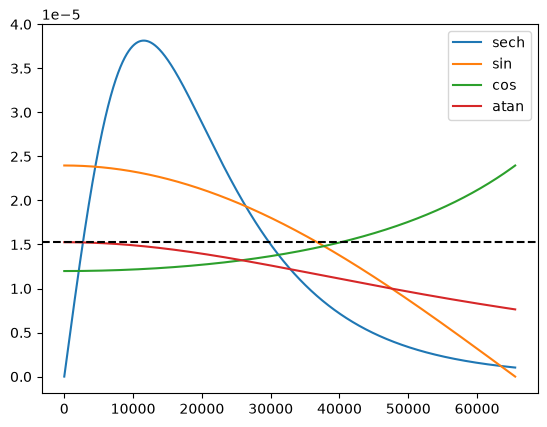

In [182]:
fig, ax = plt.subplots()
ax.plot(diff(sech,5.),label="sech")
ax.plot(diff(sin,3.1415/2),label="sin")
ax.plot(diff(tan,3.1415/4),label="cos")
def r(x) :
    return -atan((x-1)/(x+1))
ax.plot(diff(r,1.),label="atan")
plt.axhline(1./NBins,color="black", linestyle="--")
ax.legend(loc='upper right')
plt.show()

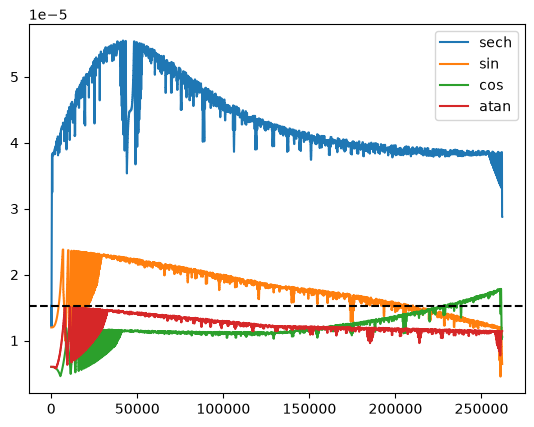

In [183]:
fig, ax = plt.subplots()
ax.plot(errq(sech,5.),label="sech")
ax.plot(errq(sin,3.1415/2),label="sin")
ax.plot(errq(tan,3.1415/4),label="cos")
def r(x) :
    return atan((x-1)/(x+1))
ax.plot(errq(r,1.),label="atan")
ax.axhline(1./NBins,color="black", linestyle="--")
ax.legend(loc='upper right')
plt.show()